# Experimentación de clasificación supervisada (Lab 02)

Este cuaderno compara **KNN, Árbol de Decisión (DT), Random Forest (RF), XGBoost y AdaBoost** sobre dos conjuntos de datos: **Diabetes** y **Potabilidad del agua**. Todo se ejecuta con la clase `ClasificacionModelos` del framework del curso (`src/supervised`).

## Criterios del experimento

- **Misma partición para todos los modelos:** 75 % entrenamiento y 25 % prueba, estratificada y con semilla fija (`random_state=42`). Así la comparación es justa y reproducible.
- **Preprocesamiento (dentro del pipeline del framework):** imputación por mediana y estandarización de variables numéricas.
- **Métrica principal: F1 macro.** Ambos datasets están desbalanceados, así que la *accuracy* sola puede engañar: un modelo que siempre predice la clase mayoritaria obtiene una accuracy alta sin aprender nada. F1 macro da el mismo peso a ambas clases.
- **Para cada algoritmo:** configuración estándar + variaciones de hiperparámetros → tabla comparativa → mejor modelo → matriz de confusión e informe por clase → análisis.

In [47]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

from supervised import ClasificacionModelos

SEMILLA = 42
TEST_SIZE = 0.25
pd.set_option("display.float_format", "{:.4f}".format)

## Funciones de apoyo

- `experimentar` ejecuta un algoritmo con varias configuraciones y devuelve una tabla ordenada por F1 macro.
- `analizar_mejor` muestra la matriz de confusión y el informe por clase de la mejor configuración.

In [48]:
def experimentar(clasificador, metodo, configuraciones):
    """Ejecuta `metodo` con cada configuración y devuelve (tabla, resultados)."""
    filas, resultados = [], {}
    for nombre, parametros in configuraciones:
        resultado = getattr(clasificador, metodo)(**parametros)
        m = resultado["metricas"]
        resultados[nombre] = resultado
        filas.append({
            "Configuración": nombre,
            "Parámetros": parametros,
            "Accuracy": m["accuracy"],
            "Precisión macro": m["precision_macro"],
            "Recall macro": m["recall_macro"],
            "F1 macro": m["f1_macro"],
        })
    tabla = (pd.DataFrame(filas)
             .sort_values(["F1 macro", "Accuracy"], ascending=False)
             .reset_index(drop=True))
    return tabla, resultados


def analizar_mejor(tabla, resultados, titulo):
    """Muestra matriz de confusión e informe por clase del mejor modelo."""
    mejor = tabla.loc[0, "Configuración"]
    m = resultados[mejor]["metricas"]
    display(Markdown(f"**Mejor configuración ({titulo}):** `{mejor}` — F1 macro = {m['f1_macro']:.4f}, Accuracy = {m['accuracy']:.4f}"))

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=np.array(m["confusion_matrix"]),
        display_labels=m["confusion_matrix_labels"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{titulo}: {mejor}")
    plt.tight_layout()
    plt.show()

    informe = pd.DataFrame(m["classification_report"]).T
    display(informe)
    return mejor

## Configuraciones a comparar

La primera configuración de cada lista es la **estándar** (los valores por defecto del framework). Las demás son **variaciones** de un hiperparámetro a la vez, para poder atribuir el cambio de desempeño a ese parámetro.

| Algoritmo | Hiperparámetros que se varían | Qué controlan |
|---|---|---|
| KNN | `n_neighbors` | Cuántos vecinos votan. Pocos → sensible al ruido; muchos → frontera muy suave |
| DT | `max_depth`, `min_samples_split` | Tamaño del árbol. Árbol muy profundo → sobreajuste |
| RF | `n_estimators`, `max_depth`, `min_samples_split` | Cantidad y tamaño de los árboles del bosque |
| XGBoost | `n_estimators`, `max_depth`, `learning_rate` | Cuántos árboles se suman, su tamaño y cuánto corrige cada uno |
| AdaBoost | `n_estimators` (+ búsqueda en cuadrícula con `learning_rate`) | Cuántos clasificadores débiles se combinan y su peso |

In [49]:
CONFIGURACIONES = {
    "knn": [
        ("Estándar (k=5)", {"n_neighbors": 5}),
        ("k=3", {"n_neighbors": 3}),
        ("k=7", {"n_neighbors": 7}),
        ("k=11", {"n_neighbors": 11}),
        ("k=15", {"n_neighbors": 15}),
        ("k=21", {"n_neighbors": 21}),
    ],
    "decision_tree": [
        ("Estándar (sin límite)", {}),
        ("max_depth=3", {"max_depth": 3}),
        ("max_depth=5", {"max_depth": 5}),
        ("max_depth=8", {"max_depth": 8}),
        ("min_samples_split=20", {"min_samples_split": 20}),
        ("max_depth=5, min_samples_split=20", {"max_depth": 5, "min_samples_split": 20}),
    ],
    "random_forest": [
        ("Estándar (200 árboles)", {}),
        ("100 árboles", {"n_estimators": 100}),
        ("500 árboles", {"n_estimators": 500}),
        ("max_depth=8", {"max_depth": 8}),
        ("min_samples_split=10", {"min_samples_split": 10}),
    ],
    "xgboost": [
        ("Estándar (120, prof 3, lr 0.1)", {}),
        ("lr=0.05, 300 árboles", {"learning_rate": 0.05, "n_estimators": 300}),
        ("lr=0.3", {"learning_rate": 0.3}),
        ("max_depth=2", {"max_depth": 2}),
        ("max_depth=5", {"max_depth": 5}),
    ],
    "adaboost": [
        ("Estándar (80)", {}),
        ("50 estimadores", {"n_estimators": 50}),
        ("150 estimadores", {"n_estimators": 150}),
        ("300 estimadores", {"n_estimators": 300}),
    ],
}

GRID_ADABOOST = {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0]}

NOMBRES = {
    "knn": "KNN",
    "decision_tree": "Árbol de Decisión",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
    "adaboost": "AdaBoost",
}

# 1. Dataset: Diabetes

Conjunto *Pima Indians Diabetes*: 768 pacientes con 8 variables clínicas. La variable objetivo `Outcome` vale 1 si la paciente tiene diabetes y 0 si no.

In [50]:
diabetes = pd.read_csv(ROOT / "data" / "diabetes.csv")
print("Dimensiones:", diabetes.shape)
print("\nDistribución de la clase objetivo (Outcome):")
print(diabetes["Outcome"].value_counts().rename("cantidad").to_frame()
      .assign(porcentaje=lambda t: (t["cantidad"] / t["cantidad"].sum() * 100).round(1)))
print("\nValores nulos por columna:")
print(diabetes.isna().sum()[lambda s: s > 0])
display(diabetes.describe().T)

Dimensiones: (768, 9)

Distribución de la clase objetivo (Outcome):
         cantidad  porcentaje
Outcome                      
0             500     65.1000
1             268     34.9000

Valores nulos por columna:
Series([], dtype: int64)


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0000,3.8451,3.3696,0.0000,1.0000,3.0000,6.0000,17.0000
Glucose,768.0000,120.8945,31.9726,0.0000,99.0000,117.0000,140.2500,199.0000
BloodPressure,768.0000,69.1055,19.3558,0.0000,62.0000,72.0000,80.0000,122.0000
SkinThickness,768.0000,20.5365,15.9522,0.0000,0.0000,23.0000,32.0000,99.0000
Insulin,768.0000,79.7995,115.2440,0.0000,0.0000,30.5000,127.2500,846.0000
BMI,768.0000,31.9926,7.8842,0.0000,27.3000,32.0000,36.6000,67.1000
DiabetesPedigreeFunction,768.0000,0.4719,0.3313,0.0780,0.2437,0.3725,0.6262,2.4200
Age,768.0000,33.2409,11.7602,21.0000,24.0000,29.0000,41.0000,81.0000
Outcome,768.0000,0.3490,0.4770,0.0000,0.0000,0.0000,1.0000,1.0000


### 1.1 Preprocesamiento

En este dataset los datos faltantes vienen codificados como **0** (por ejemplo, glucosa o presión arterial igual a 0, que es imposible en una persona viva). Se convierten a nulos para que el pipeline del framework los impute con la **mediana** del conjunto de entrenamiento, en lugar de tratarlos como valores reales.

In [51]:
COLUMNAS_CERO_INVALIDO = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Ceros (valores imposibles) antes del preprocesamiento:")
print((diabetes[COLUMNAS_CERO_INVALIDO] == 0).sum())
diabetes[COLUMNAS_CERO_INVALIDO] = diabetes[COLUMNAS_CERO_INVALIDO].replace(0, np.nan)
print("\nNulos después de convertir los ceros:")
print(diabetes.isna().sum()[lambda s: s > 0])

Ceros (valores imposibles) antes del preprocesamiento:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Nulos después de convertir los ceros:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [52]:
clf_diabetes = ClasificacionModelos(
    diabetes, target="Outcome", test_size=TEST_SIZE, random_state=SEMILLA
)
particion = clf_diabetes.prepare_data()
print(f"Entrenamiento: {len(particion.X_train)} filas | Prueba: {len(particion.X_test)} filas")
linea_base = particion.y_test.value_counts(normalize=True).max()
print(f"Línea base (predecir siempre la clase mayoritaria): accuracy = {linea_base:.4f}")

tablas_diabetes, resultados_diabetes, mejores_diabetes = {}, {}, {}

Entrenamiento: 576 filas | Prueba: 192 filas
Línea base (predecir siempre la clase mayoritaria): accuracy = 0.6510


### 1.2 KNN

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,Estándar (k=5),{'n_neighbors': 5},0.7344,0.7070,0.6921,0.6975
1,k=21,{'n_neighbors': 21},0.7396,0.7151,0.6892,0.6970
2,k=11,{'n_neighbors': 11},0.7344,0.7075,0.6887,0.6950
3,k=7,{'n_neighbors': 7},0.7240,0.6949,0.6772,0.6830
4,k=15,{'n_neighbors': 15},0.7240,0.6949,0.6772,0.6830
5,k=3,{'n_neighbors': 3},0.7135,0.6836,0.6796,0.6814


**Mejor configuración (Diabetes – KNN):** `Estándar (k=5)` — F1 macro = 0.6975, Accuracy = 0.7344

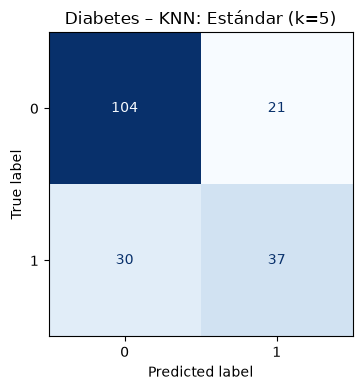

,precision,recall,f1-score,support
0,0.7761,0.8320,0.8031,125.0000
1,0.6379,0.5522,0.5920,67.0000
accuracy,0.7344,0.7344,0.7344,0.7344
macro avg,0.7070,0.6921,0.6975,192.0000
weighted avg,0.7279,0.7344,0.7294,192.0000


In [53]:
tablas_diabetes["knn"], resultados_diabetes["knn"] = experimentar(
    clf_diabetes, "knn", CONFIGURACIONES["knn"]
)
display(tablas_diabetes["knn"])
mejores_diabetes["knn"] = analizar_mejor(
    tablas_diabetes["knn"], resultados_diabetes["knn"], "Diabetes – KNN"
)

**Análisis KNN:** 





### 1.3 Árbol de Decisión (DT)

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,max_depth=5,{'max_depth': 5},0.7500,0.7247,0.7214,0.7229
1,max_depth=8,{'max_depth': 8},0.7500,0.7247,0.7214,0.7229
2,"max_depth=5, min_samples_split=20","{'max_depth': 5, 'min_samples_split': 20}",0.7396,0.7128,0.7065,0.7093
3,min_samples_split=20,{'min_samples_split': 20},0.7344,0.7075,0.6887,0.6950
4,max_depth=3,{'max_depth': 3},0.7083,0.6763,0.6513,0.6574
5,Estándar (sin límite),{},0.6875,0.6496,0.6284,0.6330


**Mejor configuración (Diabetes – Árbol de Decisión):** `max_depth=5` — F1 macro = 0.7229, Accuracy = 0.7500

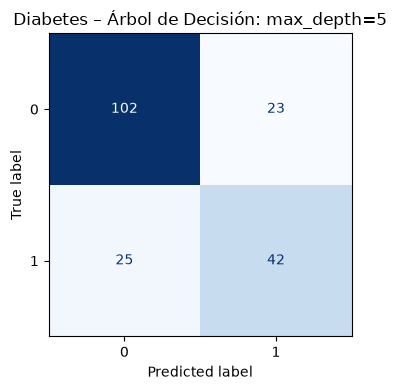

,precision,recall,f1-score,support
0,0.8031,0.8160,0.8095,125.0000
1,0.6462,0.6269,0.6364,67.0000
accuracy,0.7500,0.7500,0.7500,0.7500
macro avg,0.7247,0.7214,0.7229,192.0000
weighted avg,0.7484,0.7500,0.7491,192.0000


In [54]:
tablas_diabetes["decision_tree"], resultados_diabetes["decision_tree"] = experimentar(
    clf_diabetes, "decision_tree", CONFIGURACIONES["decision_tree"]
)
display(tablas_diabetes["decision_tree"])
mejores_diabetes["decision_tree"] = analizar_mejor(
    tablas_diabetes["decision_tree"], resultados_diabetes["decision_tree"], "Diabetes – Árbol de Decisión"
)

**Análisis Árbol de Decisión (DT):** 

Agregar aca

### 1.4 Random Forest (RF)

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,100 árboles,{'n_estimators': 100},0.7500,0.7259,0.7076,0.7141
1,min_samples_split=10,{'min_samples_split': 10},0.7448,0.7189,0.7070,0.7118
2,max_depth=8,{'max_depth': 8},0.7500,0.7269,0.7041,0.7117
3,Estándar (200 árboles),{},0.7448,0.7201,0.7001,0.7069
4,500 árboles,{'n_estimators': 500},0.7396,0.7135,0.6961,0.7022


**Mejor configuración (Diabetes – Random Forest):** `100 árboles` — F1 macro = 0.7141, Accuracy = 0.7500

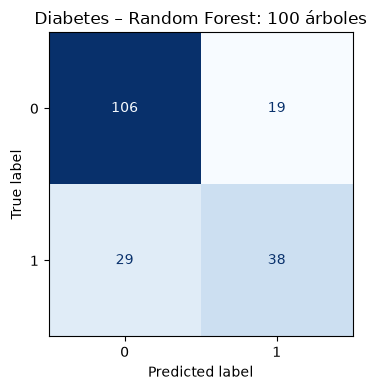

,precision,recall,f1-score,support
0,0.7852,0.8480,0.8154,125.0000
1,0.6667,0.5672,0.6129,67.0000
accuracy,0.7500,0.7500,0.7500,0.7500
macro avg,0.7259,0.7076,0.7141,192.0000
weighted avg,0.7438,0.7500,0.7447,192.0000


In [55]:
tablas_diabetes["random_forest"], resultados_diabetes["random_forest"] = experimentar(
    clf_diabetes, "random_forest", CONFIGURACIONES["random_forest"]
)
display(tablas_diabetes["random_forest"])
mejores_diabetes["random_forest"] = analizar_mejor(
    tablas_diabetes["random_forest"], resultados_diabetes["random_forest"], "Diabetes – Random Forest"
)

**Análisis Random Forest (RF):** Agregar aca

### 1.5 XGBoost

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,"lr=0.05, 300 árboles","{'learning_rate': 0.05, 'n_estimators': 300}",0.7552,0.7306,0.7220,0.7257
1,lr=0.3,{'learning_rate': 0.3},0.7500,0.7249,0.7249,0.7249
2,"Estándar (120, prof 3, lr 0.1)",{},0.7500,0.7246,0.7180,0.7209
3,max_depth=5,{'max_depth': 5},0.7344,0.7070,0.7025,0.7046
4,max_depth=2,{'max_depth': 2},0.7448,0.7210,0.6967,0.7044


**Mejor configuración (Diabetes – XGBoost):** `lr=0.05, 300 árboles` — F1 macro = 0.7257, Accuracy = 0.7552

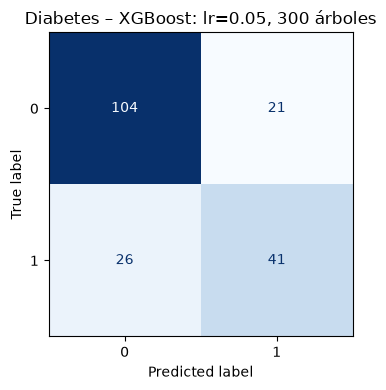

,precision,recall,f1-score,support
0,0.8000,0.8320,0.8157,125.0000
1,0.6613,0.6119,0.6357,67.0000
accuracy,0.7552,0.7552,0.7552,0.7552
macro avg,0.7306,0.7220,0.7257,192.0000
weighted avg,0.7516,0.7552,0.7529,192.0000


In [56]:
tablas_diabetes["xgboost"], resultados_diabetes["xgboost"] = experimentar(
    clf_diabetes, "xgboost", CONFIGURACIONES["xgboost"]
)
display(tablas_diabetes["xgboost"])
mejores_diabetes["xgboost"] = analizar_mejor(
    tablas_diabetes["xgboost"], resultados_diabetes["xgboost"], "Diabetes – XGBoost"
)

**Análisis XGBoost:** 


Agregar aca

### 1.6 AdaBoost

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,150 estimadores,{'n_estimators': 150},0.7448,0.7189,0.7070,0.7118
1,Estándar (80),{},0.7396,0.7135,0.6961,0.7022
2,50 estimadores,{'n_estimators': 50},0.7396,0.7135,0.6961,0.7022
3,300 estimadores,{'n_estimators': 300},0.7240,0.6949,0.6772,0.6830


**Mejor configuración (Diabetes – AdaBoost):** `150 estimadores` — F1 macro = 0.7118, Accuracy = 0.7448

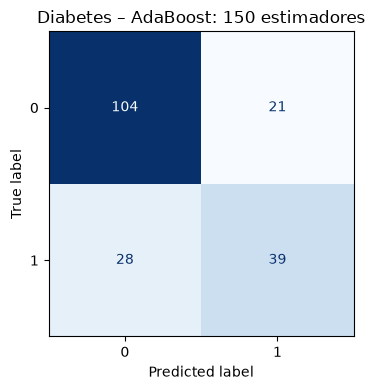

,precision,recall,f1-score,support
0,0.7879,0.8320,0.8093,125.0000
1,0.6500,0.5821,0.6142,67.0000
accuracy,0.7448,0.7448,0.7448,0.7448
macro avg,0.7189,0.7070,0.7118,192.0000
weighted avg,0.7398,0.7448,0.7412,192.0000


In [57]:
tablas_diabetes["adaboost"], resultados_diabetes["adaboost"] = experimentar(
    clf_diabetes, "adaboost", CONFIGURACIONES["adaboost"]
)
display(tablas_diabetes["adaboost"])
mejores_diabetes["adaboost"] = analizar_mejor(
    tablas_diabetes["adaboost"], resultados_diabetes["adaboost"], "Diabetes – AdaBoost"
)

Además de las variaciones manuales, se usa `adaboost_grid`, que prueba todas las combinaciones de `GRID_ADABOOST` con **validación cruzada** sobre el conjunto de entrenamiento y evalúa la mejor en el conjunto de prueba.

In [58]:
grid_diabetes = clf_diabetes.adaboost_grid(GRID_ADABOOST, cv=5)
print("Mejores parámetros (validación cruzada):", grid_diabetes["best_params"])
print(f"Score medio en validación cruzada: {grid_diabetes['best_cv_score']:.4f}")
mg = grid_diabetes["metricas"]
print(f"En prueba -> Accuracy: {mg['accuracy']:.4f} | F1 macro: {mg['f1_macro']:.4f}")

Mejores parámetros (validación cruzada): {'learning_rate': 0.1, 'n_estimators': 100}
Score medio en validación cruzada: 0.7761
En prueba -> Accuracy: 0.7292 | F1 macro: 0.6723


**Análisis AdaBoost:** 




Agregar aca

### 1.7 Comparación final de los mejores modelos — Diabetes

,Algoritmo,Mejor configuración,Accuracy,Precisión macro,Recall macro,F1 macro
0,XGBoost,"lr=0.05, 300 árboles",0.7552,0.7306,0.7220,0.7257
1,Árbol de Decisión,max_depth=5,0.7500,0.7247,0.7214,0.7229
2,Random Forest,100 árboles,0.7500,0.7259,0.7076,0.7141
3,AdaBoost,150 estimadores,0.7448,0.7189,0.7070,0.7118
4,KNN,Estándar (k=5),0.7344,0.7070,0.6921,0.6975


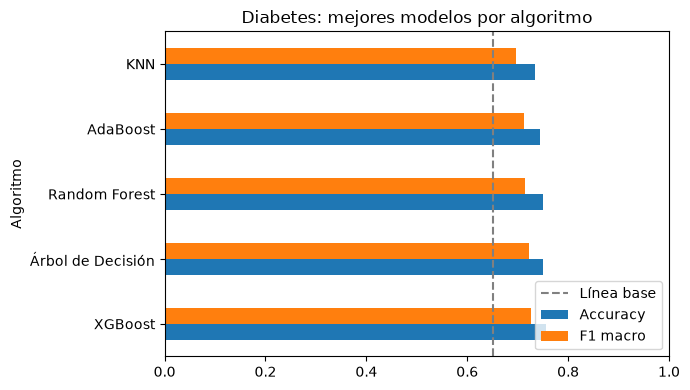

In [59]:
filas = []
for alg, mejor in mejores_diabetes.items():
    m = resultados_diabetes[alg][mejor]["metricas"]
    filas.append({
        "Algoritmo": NOMBRES[alg],
        "Mejor configuración": mejor,
        "Accuracy": m["accuracy"],
        "Precisión macro": m["precision_macro"],
        "Recall macro": m["recall_macro"],
        "F1 macro": m["f1_macro"],
    })
comparacion_diabetes = (pd.DataFrame(filas)
                    .sort_values("F1 macro", ascending=False)
                    .reset_index(drop=True))
display(comparacion_diabetes)

ax = comparacion_diabetes.set_index("Algoritmo")[["Accuracy", "F1 macro"]].plot.barh(figsize=(7, 4))
ax.axvline(linea_base, color="gray", linestyle="--", label="Línea base")
ax.set_xlim(0, 1)
ax.set_title("Diabetes: mejores modelos por algoritmo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Análisis comparativo Diabetes:**


agregar aca 





# 2. Dataset: Potabilidad del agua

Conjunto *Water Potability*: 3276 muestras de agua con 9 mediciones fisicoquímicas. La variable objetivo `Potability` vale 1 si el agua es potable y 0 si no.

In [60]:
agua = pd.read_csv(ROOT / "data" / "water_potability.csv")
print("Dimensiones:", agua.shape)
print("\nDistribución de la clase objetivo (Potability):")
print(agua["Potability"].value_counts().rename("cantidad").to_frame()
      .assign(porcentaje=lambda t: (t["cantidad"] / t["cantidad"].sum() * 100).round(1)))
print("\nValores nulos por columna:")
print(agua.isna().sum()[lambda s: s > 0])
display(agua.describe().T)

Dimensiones: (3276, 10)

Distribución de la clase objetivo (Potability):
            cantidad  porcentaje
Potability                      
0               1998     61.0000
1               1278     39.0000

Valores nulos por columna:
ph                 491
Sulfate            781
Trihalomethanes    162
dtype: int64


,count,mean,std,min,25%,50%,75%,max
ph,2785.0000,7.0808,1.5943,0.0000,6.0931,7.0368,8.0621,14.0000
Hardness,3276.0000,196.3695,32.8798,47.4320,176.8505,196.9676,216.6675,323.1240
Solids,3276.0000,22014.0925,8768.5708,320.9426,15666.6903,20927.8336,27332.7621,61227.1960
Chloramines,3276.0000,7.1223,1.5831,0.3520,6.1274,7.1303,8.1149,13.1270
Sulfate,2495.0000,333.7758,41.4168,129.0000,307.6995,333.0735,359.9502,481.0306
Conductivity,3276.0000,426.2051,80.8241,181.4838,365.7344,421.8850,481.7923,753.3426
Organic_carbon,3276.0000,14.2850,3.3082,2.2000,12.0658,14.2183,16.5577,28.3000
Trihalomethanes,3114.0000,66.3963,16.1750,0.7380,55.8445,66.6225,77.3375,124.0000
Turbidity,3276.0000,3.9668,0.7804,1.4500,3.4397,3.9550,4.5003,6.7390
Potability,3276.0000,0.3901,0.4878,0.0000,0.0000,0.0000,1.0000,1.0000


### 2.1 Preprocesamiento

Este dataset tiene valores nulos reales en `ph`, `Sulfate` y `Trihalomethanes`. No se eliminan filas (se perdería mucha información); el pipeline del framework los **imputa con la mediana** calculada solo con el conjunto de entrenamiento, para no filtrar información del conjunto de prueba.

In [61]:
print("Porcentaje de nulos por columna:")
print((agua.isna().mean() * 100).round(1)[lambda s: s > 0])

Porcentaje de nulos por columna:
ph                15.0000
Sulfate           23.8000
Trihalomethanes    4.9000
dtype: float64


In [62]:
clf_agua = ClasificacionModelos(
    agua, target="Potability", test_size=TEST_SIZE, random_state=SEMILLA
)
particion = clf_agua.prepare_data()
print(f"Entrenamiento: {len(particion.X_train)} filas | Prueba: {len(particion.X_test)} filas")
linea_base = particion.y_test.value_counts(normalize=True).max()
print(f"Línea base (predecir siempre la clase mayoritaria): accuracy = {linea_base:.4f}")

tablas_agua, resultados_agua, mejores_agua = {}, {}, {}

Entrenamiento: 2457 filas | Prueba: 819 filas
Línea base (predecir siempre la clase mayoritaria): accuracy = 0.6093


### 2.2 KNN

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,k=3,{'n_neighbors': 3},0.6081,0.5773,0.5691,0.5685
1,Estándar (k=5),{'n_neighbors': 5},0.6093,0.5742,0.5605,0.5563
2,k=15,{'n_neighbors': 15},0.6410,0.6233,0.5709,0.5521
3,k=7,{'n_neighbors': 7},0.6020,0.5615,0.5467,0.5379
4,k=21,{'n_neighbors': 21},0.6398,0.6275,0.5637,0.5369
5,k=11,{'n_neighbors': 11},0.6178,0.5812,0.5513,0.5336


**Mejor configuración (Potabilidad del agua – KNN):** `k=3` — F1 macro = 0.5685, Accuracy = 0.6081

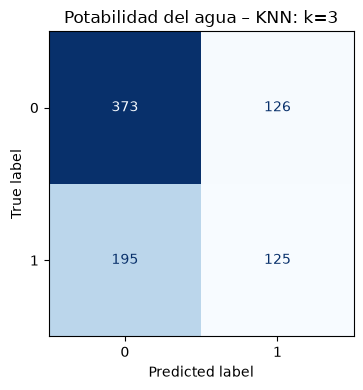

,precision,recall,f1-score,support
0,0.6567,0.7475,0.6992,499.0000
1,0.4980,0.3906,0.4378,320.0000
accuracy,0.6081,0.6081,0.6081,0.6081
macro avg,0.5773,0.5691,0.5685,819.0000
weighted avg,0.5947,0.6081,0.5971,819.0000


In [63]:
tablas_agua["knn"], resultados_agua["knn"] = experimentar(
    clf_agua, "knn", CONFIGURACIONES["knn"]
)
display(tablas_agua["knn"])
mejores_agua["knn"] = analizar_mejor(
    tablas_agua["knn"], resultados_agua["knn"], "Potabilidad del agua – KNN"
)

**Análisis KNN:** 




Agregar aca

### 2.3 Árbol de Decisión (DT)

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,min_samples_split=20,{'min_samples_split': 20},0.5849,0.5683,0.5696,0.5686
1,Estándar (sin límite),{},0.5592,0.5426,0.5436,0.5426
2,max_depth=5,{'max_depth': 5},0.6374,0.6445,0.5505,0.5046
3,"max_depth=5, min_samples_split=20","{'max_depth': 5, 'min_samples_split': 20}",0.6349,0.6428,0.5463,0.4960
4,max_depth=8,{'max_depth': 8},0.6190,0.5858,0.5366,0.4957
5,max_depth=3,{'max_depth': 3},0.6215,0.6557,0.5201,0.4321


**Mejor configuración (Potabilidad del agua – Árbol de Decisión):** `min_samples_split=20` — F1 macro = 0.5686, Accuracy = 0.5849

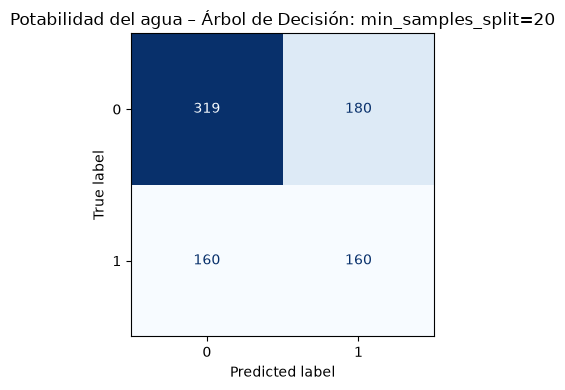

,precision,recall,f1-score,support
0,0.6660,0.6393,0.6524,499.0000
1,0.4706,0.5000,0.4848,320.0000
accuracy,0.5849,0.5849,0.5849,0.5849
macro avg,0.5683,0.5696,0.5686,819.0000
weighted avg,0.5896,0.5849,0.5869,819.0000


In [64]:
tablas_agua["decision_tree"], resultados_agua["decision_tree"] = experimentar(
    clf_agua, "decision_tree", CONFIGURACIONES["decision_tree"]
)
display(tablas_agua["decision_tree"])
mejores_agua["decision_tree"] = analizar_mejor(
    tablas_agua["decision_tree"], resultados_agua["decision_tree"], "Potabilidad del agua – Árbol de Decisión"
)

**Análisis Árbol de Decisión (DT):** 



Agregar aca

### 2.4 Random Forest (RF)

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,min_samples_split=10,{'min_samples_split': 10},0.6728,0.6721,0.6093,0.6012
1,500 árboles,{'n_estimators': 500},0.6740,0.6755,0.6097,0.6012
2,Estándar (200 árboles),{},0.6728,0.6730,0.6087,0.6002
3,100 árboles,{'n_estimators': 100},0.6642,0.6544,0.6034,0.5963
4,max_depth=8,{'max_depth': 8},0.6581,0.6962,0.5743,0.5385


**Mejor configuración (Potabilidad del agua – Random Forest):** `min_samples_split=10` — F1 macro = 0.6012, Accuracy = 0.6728

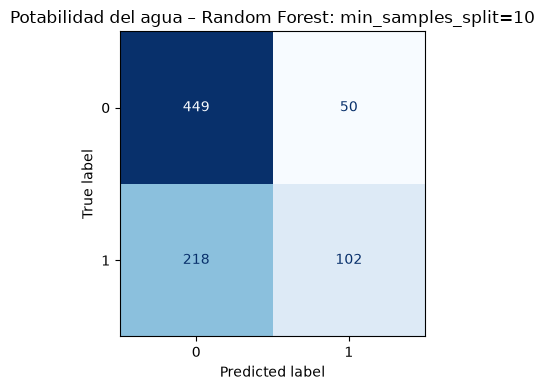

,precision,recall,f1-score,support
0,0.6732,0.8998,0.7702,499.0000
1,0.6711,0.3187,0.4322,320.0000
accuracy,0.6728,0.6728,0.6728,0.6728
macro avg,0.6721,0.6093,0.6012,819.0000
weighted avg,0.6723,0.6728,0.6381,819.0000


In [65]:
tablas_agua["random_forest"], resultados_agua["random_forest"] = experimentar(
    clf_agua, "random_forest", CONFIGURACIONES["random_forest"]
)
display(tablas_agua["random_forest"])
mejores_agua["random_forest"] = analizar_mejor(
    tablas_agua["random_forest"], resultados_agua["random_forest"], "Potabilidad del agua – Random Forest"
)

**Análisis Random Forest (RF):** 


Agregar aca

### 2.5 XGBoost

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,max_depth=5,{'max_depth': 5},0.6581,0.6424,0.6001,0.5942
1,lr=0.3,{'learning_rate': 0.3},0.6435,0.6188,0.5908,0.5869
2,"Estándar (120, prof 3, lr 0.1)",{},0.6654,0.6737,0.5937,0.5767
3,"lr=0.05, 300 árboles","{'learning_rate': 0.05, 'n_estimators': 300}",0.6593,0.6572,0.5898,0.5743
4,max_depth=2,{'max_depth': 2},0.6398,0.6375,0.5581,0.5224


**Mejor configuración (Potabilidad del agua – XGBoost):** `max_depth=5` — F1 macro = 0.5942, Accuracy = 0.6581

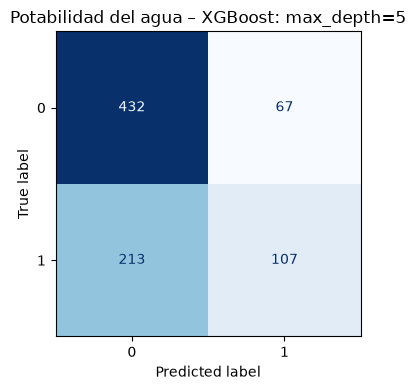

,precision,recall,f1-score,support
0,0.6698,0.8657,0.7552,499.0000
1,0.6149,0.3344,0.4332,320.0000
accuracy,0.6581,0.6581,0.6581,0.6581
macro avg,0.6424,0.6001,0.5942,819.0000
weighted avg,0.6483,0.6581,0.6294,819.0000


In [66]:
tablas_agua["xgboost"], resultados_agua["xgboost"] = experimentar(
    clf_agua, "xgboost", CONFIGURACIONES["xgboost"]
)
display(tablas_agua["xgboost"])
mejores_agua["xgboost"] = analizar_mejor(
    tablas_agua["xgboost"], resultados_agua["xgboost"], "Potabilidad del agua – XGBoost"
)

**Análisis XGBoost:** _(Escribir aquí 2–4 líneas. ¿Cómo afectó el learning_rate y la profundidad? ¿Hay señales de sobreajuste con árboles más profundos o lr alto?)_

### 2.6 AdaBoost

,Configuración,Parámetros,Accuracy,Precisión macro,Recall macro,F1 macro
0,300 estimadores,{'n_estimators': 300},0.6190,0.5949,0.5271,0.4655
1,50 estimadores,{'n_estimators': 50},0.6178,0.5975,0.5221,0.4504
2,150 estimadores,{'n_estimators': 150},0.6178,0.5975,0.5221,0.4504
3,Estándar (80),{},0.6166,0.5938,0.5200,0.4454


**Mejor configuración (Potabilidad del agua – AdaBoost):** `300 estimadores` — F1 macro = 0.4655, Accuracy = 0.6190

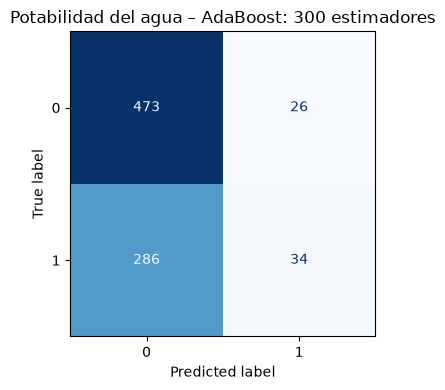

,precision,recall,f1-score,support
0,0.6232,0.9479,0.7520,499.0000
1,0.5667,0.1062,0.1789,320.0000
accuracy,0.6190,0.6190,0.6190,0.6190
macro avg,0.5949,0.5271,0.4655,819.0000
weighted avg,0.6011,0.6190,0.5281,819.0000


In [67]:
tablas_agua["adaboost"], resultados_agua["adaboost"] = experimentar(
    clf_agua, "adaboost", CONFIGURACIONES["adaboost"]
)
display(tablas_agua["adaboost"])
mejores_agua["adaboost"] = analizar_mejor(
    tablas_agua["adaboost"], resultados_agua["adaboost"], "Potabilidad del agua – AdaBoost"
)

Además de las variaciones manuales, se usa `adaboost_grid`, que prueba todas las combinaciones de `GRID_ADABOOST` con **validación cruzada** sobre el conjunto de entrenamiento y evalúa la mejor en el conjunto de prueba.

In [68]:
grid_agua = clf_agua.adaboost_grid(GRID_ADABOOST, cv=5)
print("Mejores parámetros (validación cruzada):", grid_agua["best_params"])
print(f"Score medio en validación cruzada: {grid_agua['best_cv_score']:.4f}")
mg = grid_agua["metricas"]
print(f"En prueba -> Accuracy: {mg['accuracy']:.4f} | F1 macro: {mg['f1_macro']:.4f}")

Mejores parámetros (validación cruzada): {'learning_rate': 1.0, 'n_estimators': 200}
Score medio en validación cruzada: 0.6182
En prueba -> Accuracy: 0.6203 | F1 macro: 0.4602


**Análisis AdaBoost:**



Agregar aca

### 2.7 Comparación final de los mejores modelos — Potabilidad del agua

,Algoritmo,Mejor configuración,Accuracy,Precisión macro,Recall macro,F1 macro
0,Random Forest,min_samples_split=10,0.6728,0.6721,0.6093,0.6012
1,XGBoost,max_depth=5,0.6581,0.6424,0.6001,0.5942
2,Árbol de Decisión,min_samples_split=20,0.5849,0.5683,0.5696,0.5686
3,KNN,k=3,0.6081,0.5773,0.5691,0.5685
4,AdaBoost,300 estimadores,0.6190,0.5949,0.5271,0.4655


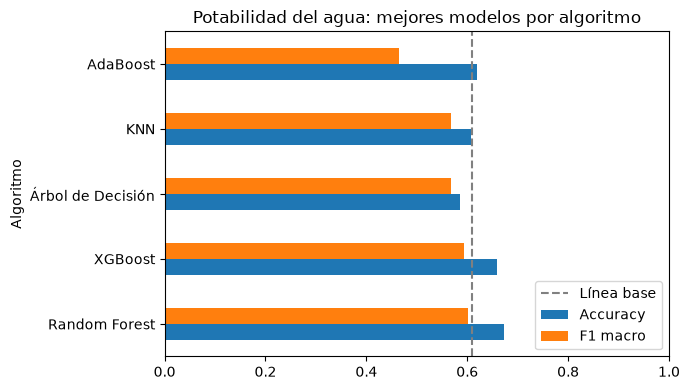

In [71]:
filas = []
for alg, mejor in mejores_agua.items():
    m = resultados_agua[alg][mejor]["metricas"]
    filas.append({
        "Algoritmo": NOMBRES[alg],
        "Mejor configuración": mejor,
        "Accuracy": m["accuracy"],
        "Precisión macro": m["precision_macro"],
        "Recall macro": m["recall_macro"],
        "F1 macro": m["f1_macro"],
    })
comparacion_agua = (pd.DataFrame(filas)
                    .sort_values("F1 macro", ascending=False)
                    .reset_index(drop=True))
display(comparacion_agua)

ax = comparacion_agua.set_index("Algoritmo")[["Accuracy", "F1 macro"]].plot.barh(figsize=(7, 4))
ax.axvline(linea_base, color="gray", linestyle="--", label="Línea base")
ax.set_xlim(0, 1)
ax.set_title("Potabilidad del agua: mejores modelos por algoritmo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Análisis comparativo Potabilidad del agua:**


Agregar aca

# 3. Conclusiones generales


Agregar aca
